In [1]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [2]:
import json
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
NUM_CLASSES = 38

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795627449.005270   81295 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795627449.045307   81295 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795627450.063376   81295 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
train_data = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

valid_data = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_data.class_names

print("Number of classes:", len(class_names))
print(class_names[:5])

Found 70295 files belonging to 38 classes.


I0000 00:00:1795627463.065411   81295 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1201 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 17572 files belonging to 38 classes.
Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_batch(images, labels):
    images = preprocess_input(images)
    return images, labels

train_data = train_data.map(
    prepare_batch,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

valid_data = valid_data.map(
    prepare_batch,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("ResNet50 preprocessing applied.")

ResNet50 preprocessing applied.


In [5]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 118s 1us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,122,022 (92.02 MB)

 Trainable params: 534,310 (2.04 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [6]:
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath="models/best_resnet50_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Callbacks are ready.")

Callbacks are ready.


In [7]:
history = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/5


/home/anshul/crop-disease-detection/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795627786.363827   81443 service.cc:153] XLA service 0x703148067bc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795627786.363883   81443 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795627786.591793   81443 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795627788.074087   81443 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795627788.185500   81443 dot

   2/2197 ━━━━━━━━━━━━━━━━━━━━ 2:25 66ms/step - accuracy: 0.0312 - loss: 4.6795       

I0000 00:00:1795627809.061480   81443 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2196/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8808 - loss: 0.3840

I0000 00:00:1795627957.477026   81443 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11101__.183
W0000 00:00:1795627969.567906   81443 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.16GiB (rounded to 1243349504)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1795627969.567964   81443 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1795627969.567966   81443 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 94, Chunks in use: 94. 23.5KiB allocated for chunks. 23.5KiB in use in bin. 9.6KiB client-requested in use in bin.
I0000 00:00:1795627969.567971   81443 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 41, Chunks in use: 40. 20.5KiB allocated for chunks. 20.0KiB in use in bin. 20.0KiB client-requested in use in bin.
I0

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8809 - loss: 0.3840

I0000 00:00:1795627982.892540   81442 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.



Epoch 1: val_accuracy improved from None to 0.95328, saving model to models/best_resnet50_model.keras

Epoch 1: finished saving model to models/best_resnet50_model.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 248s 101ms/step - accuracy: 0.8809 - loss: 0.3840 - val_accuracy: 0.9533 - val_loss: 0.1385 - learning_rate: 0.0010
Epoch 2/5
2196/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9383 - loss: 0.1854
Epoch 2: val_accuracy improved from 0.95328 to 0.97183, saving model to models/best_resnet50_model.keras

Epoch 2: finished saving model to models/best_resnet50_model.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 184s 84ms/step - accuracy: 0.9383 - loss: 0.1855 - val_accuracy: 0.9718 - val_loss: 0.0822 - learning_rate: 0.0010
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9468 - loss: 0.1598
Epoch 3: val_accuracy did not improve from 0.97183
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 185s 84ms/step - accuracy: 0.9468 - loss: 0.1598 - val_accuracy: 0.9713 - val_loss: 0.0803 - learning_rat

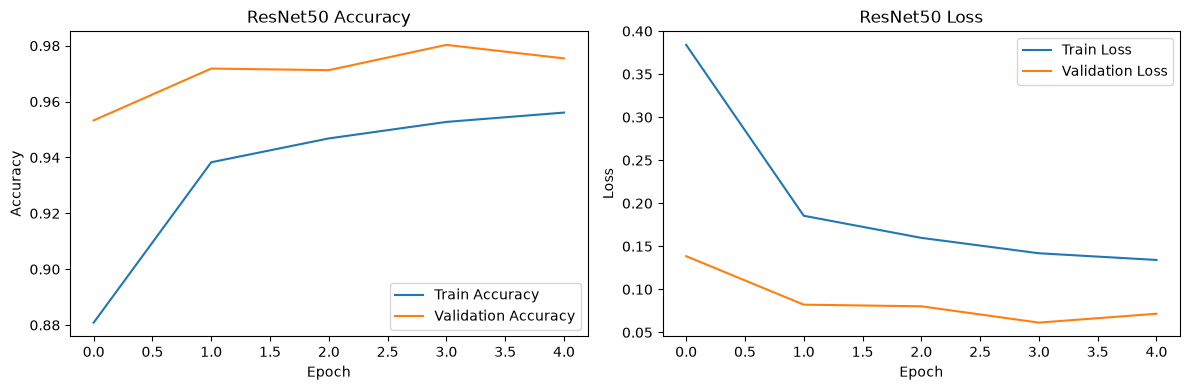

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
import json

resnet_results = {
    "best_val_accuracy": max(history.history["val_accuracy"]),
    "best_val_loss": min(history.history["val_loss"]),
    "epochs_completed": len(history.history["loss"])
}

with open("results/resnet50_results.json", "w") as f:
    json.dump(resnet_results, f, indent=4)

model.save("models/resnet50_crop_disease.keras")

print("ResNet50 model saved.")
print(resnet_results)

ResNet50 model saved.
{'best_val_accuracy': 0.9803096055984497, 'best_val_loss': 0.06134919077157974, 'epochs_completed': 5}


In [10]:
import json

resnet_results = {
    "best_val_accuracy": max(history.history["val_accuracy"]),
    "best_val_loss": min(history.history["val_loss"]),
    "epochs_completed": len(history.history["loss"])
}

with open("results/resnet50_results.json", "w") as f:
    json.dump(resnet_results, f, indent=4)

model.save("models/resnet50_crop_disease.keras")

print("ResNet50 model saved.")
print(resnet_results)

ResNet50 model saved.
{'best_val_accuracy': 0.9803096055984497, 'best_val_loss': 0.06134919077157974, 'epochs_completed': 5}
